In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/README.dataset.txt
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/README.roboflow.txt
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/data.yaml
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2289_jpeg_jpg.rf.fe2a7a149e7b11f2313f5a7b30386e85.jpg
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2301_jpeg_jpg.rf.2c19ae5efbd1f8611b5578125f001695.jpg
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2319_jpeg_jpg.rf.6e20bf97d17b74a8948aa48776c40454.jpg
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2347_jpeg_jpg.rf.7c71ac4b9301eb358cd4a832844dedcb.jpg
/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2354_jpeg_jpg.rf.396e872c7fb0a95e911806986995ee7a.jpg
/kaggle/i

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
import shutil
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


# 训练水下生物检测模型

In [5]:
model = YOLO('yolo11n.pt')

In [6]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/data.yaml \
    epochs = 100 \
    imgsz = 640 \
    batch = 64 \
    device = 0,1

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.

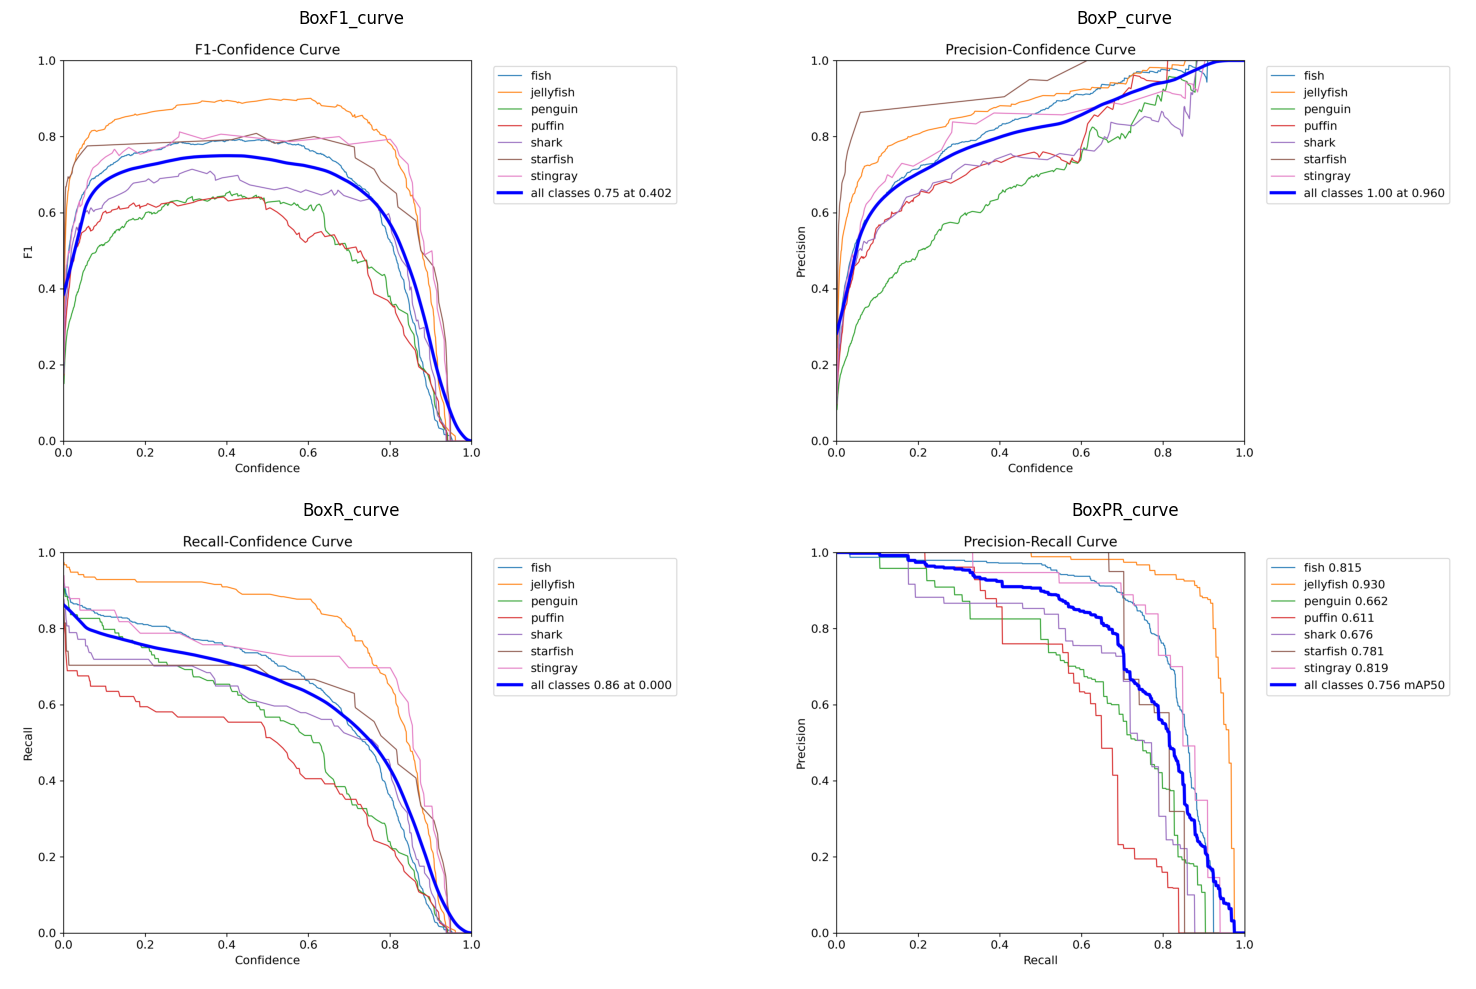

In [7]:
# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到对应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0])
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

plt.tight_layout()
plt.show()

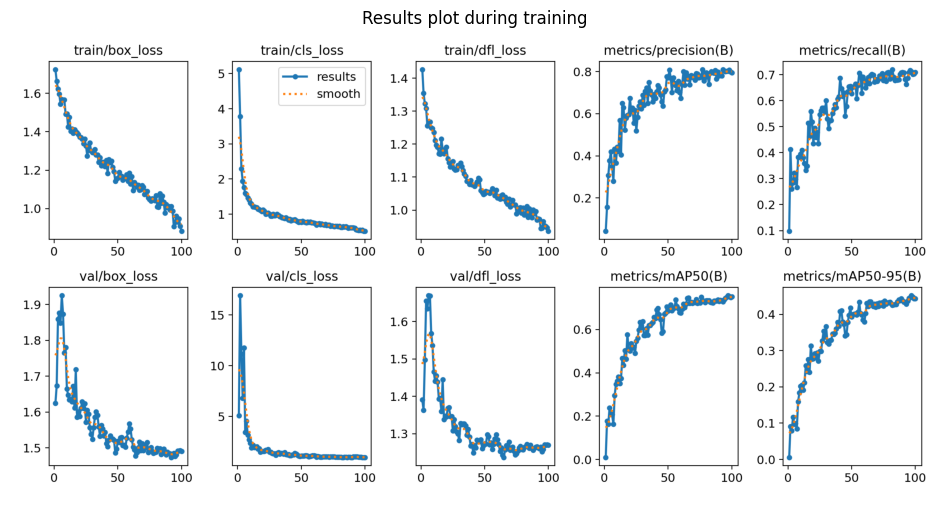

In [8]:
# results.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'
# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title('Results plot during training')
plt.axis('off')
plt.show()

In [9]:
# 加载训练好的最佳模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 模型验证
metrics = model.val(data = '/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/data.yaml')

Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,509 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 124.0±85.1 MB/s, size: 71.6 KB)
val: Scanning /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/valid/labels... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 766.0it/s 0.2s2s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.6it/s 2.2s0.2ss
                   all        127        909      0.803      0.707      0.757      0.451
                  fish         63        459      0.831      0.749      0.815      0.452
             jellyfish          9        155      0.869      0.898      0.919      0.526
               penguin 

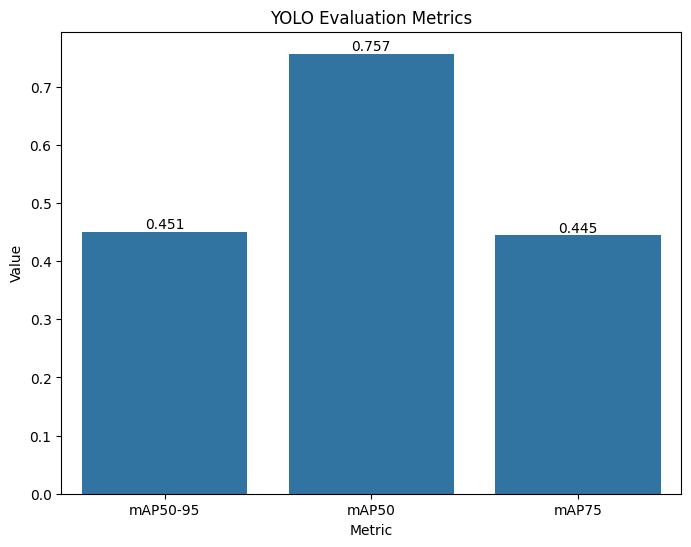

In [11]:
%matplotlib inline
# 创建柱状图
ax = sns.barplot(
    x = ['mAP50-95', 'mAP50', 'mAP75'],
    y = [metrics.box.map, metrics.box.map50, metrics.box.map75]
)
# 设置标题和轴标签
ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')
fig = plt.gcf()
fig.set_size_inches(8, 6)
# 在柱状图上添加数值
for p in ax.patches:
    ax.annotate(
        '{:.3f}'.format(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center', va = 'bottom'
    )
# 显示图形
plt.show()

In [12]:
# 定义测试图片目录的路径
datasets_path = '/kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain'
test_img_dir = os.path.join(datasets_path, 'test/images')

def pred_images_show(images = test_img_dir, num_sample = 16):
    # 获取图片目录中的所有图片文件名
    image_files = os.listdir(images)
    # 随机选择指定数量的图片文件
    rand_imgs = random.sample(image_files, num_sample)

    # 创建一个 4 * 4 的图布局，用于显示图片
    fig, axes = plt.subplots(4, 4, figsize = (16, 16))
    # 遍历每个样本图片
    for i in range(num_sample):
        # 获取当前图片文件名
        image = rand_imgs[i]
        # 确定当前图片在图布局中的位置
        ax = axes[i // 4, i % 4]
        # 使用模型对当前图片进行预测
        result_predict = model.predict(source = os.path.join(images, image))
        # 将预测结果的图片绘制在子图中
        ax.imshow(cv2.cvtColor(result_predict[0].plot(), cv2.COLOR_BGR2RGB))
        # 关闭子图的坐标轴
        ax.axis('off')
    # 调整图布局，使其紧凑
    plt.tight_layout()
    # 显示图片
    plt.show()


image 1/1 /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_3154_jpeg_jpg.rf.5f429a366c02d38bc9e2217f4508c3e0.jpg: 640x480 1 fish, 1 puffin, 9.5ms
Speed: 3.8ms preprocess, 9.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_8452_jpg.rf.6bbff701ab93e29553b3a70137fd4e66.jpg: 480x640 40 fishs, 46.6ms
Speed: 1.8ms preprocess, 46.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_2465_jpeg_jpg.rf.7e699ec1d2e373d93dac32cd02db9438.jpg: 640x480 18 jellyfishs, 10.6ms
Speed: 1.9ms preprocess, 10.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /kaggle/input/datasets/slavkoprytula/aquarium-data-cots/aquarium_pretrain/test/images/IMG_8590_MOV-2_jpg.rf.2136fdb5dcbcd58a1dc456bb3e5bf476.jpg: 640

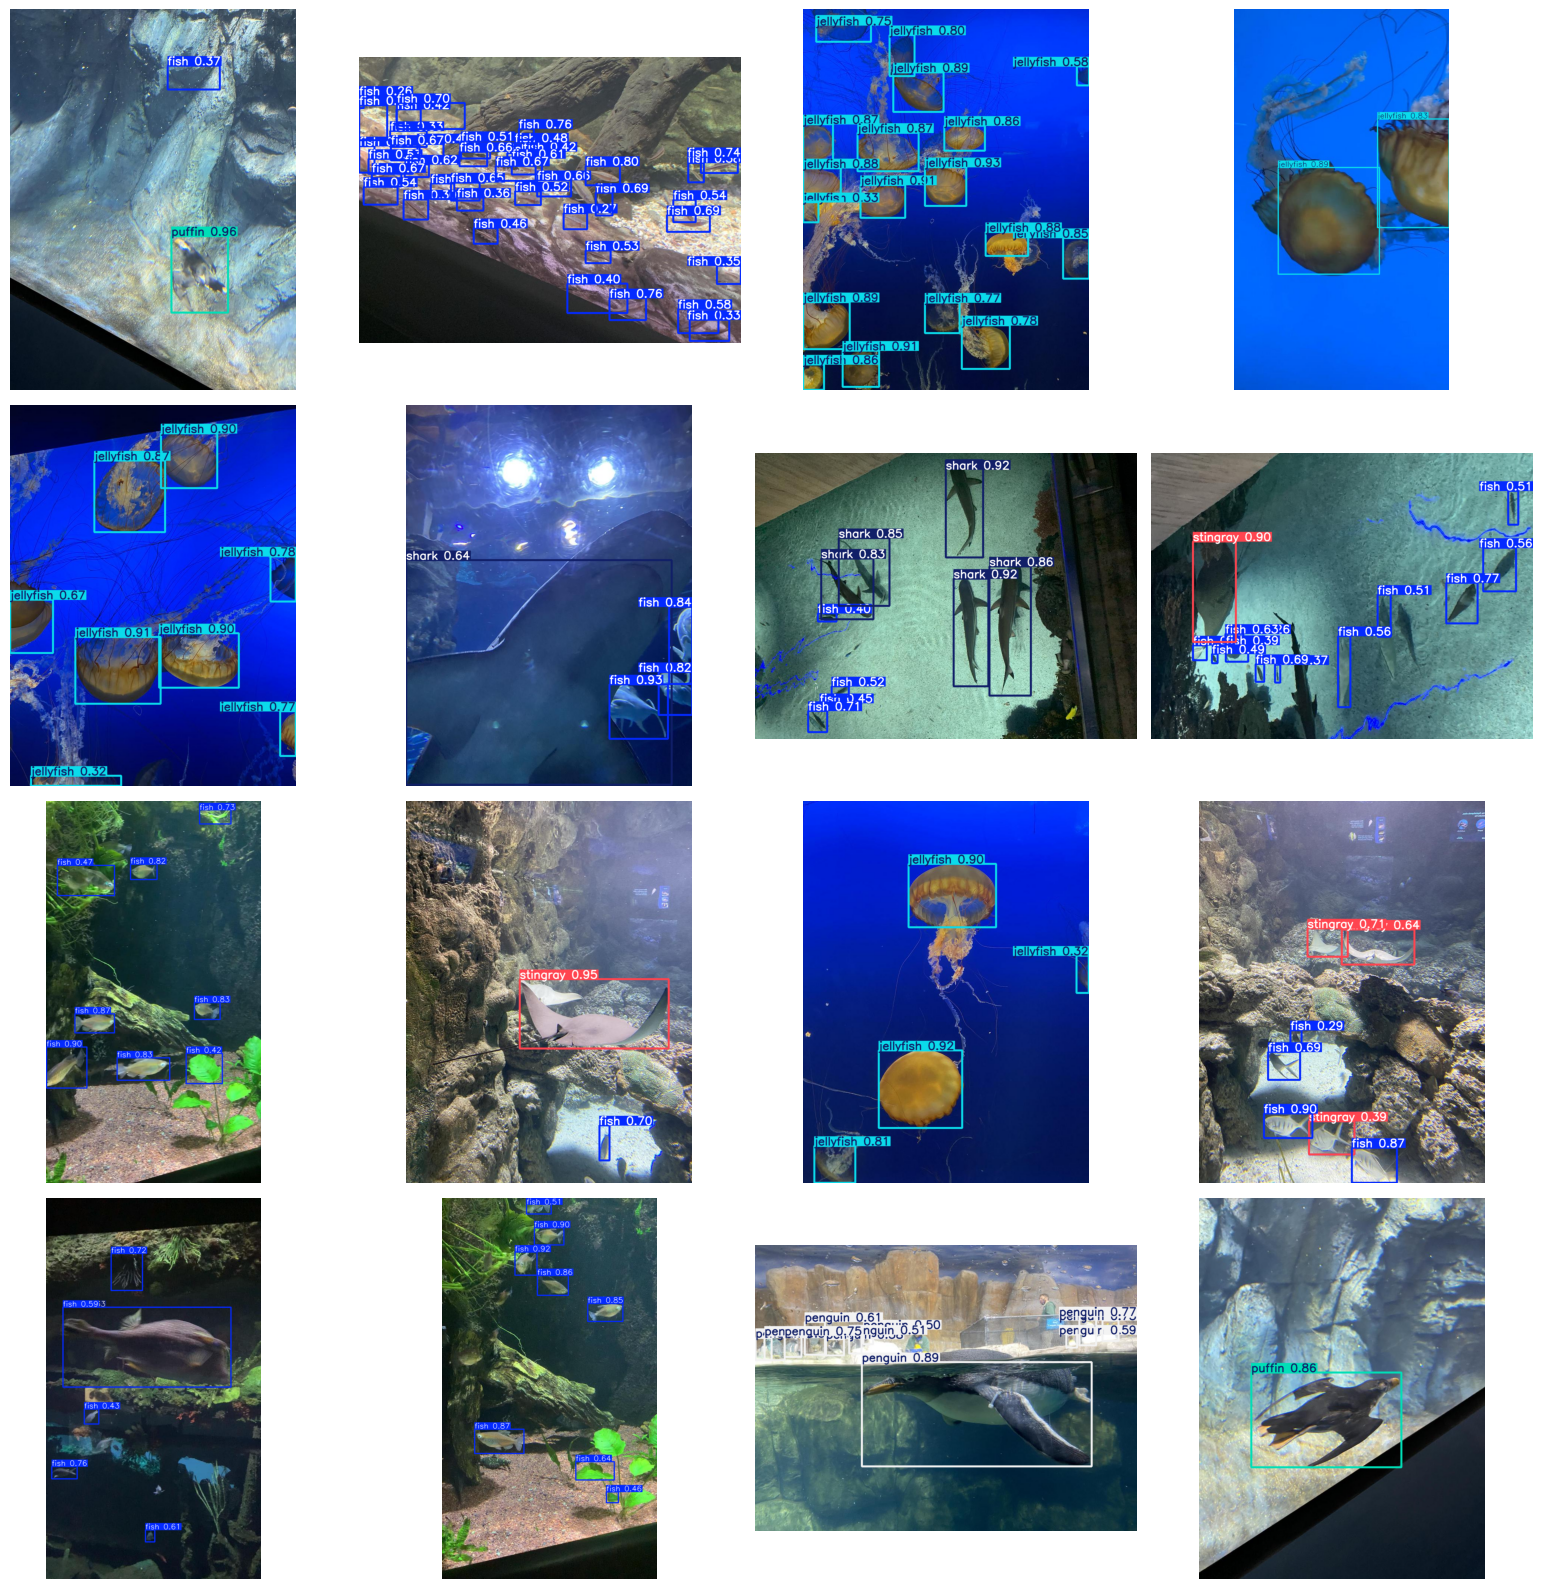

In [13]:
# 调用函数显示预测图片 
pred_images_show()

In [14]:
!zip -q -r results.zip /kaggle/working/*